<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/QSVM_MalwareDetection_Kratka2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QSVM for malware detection: Kratka and Gabris (2025) step by step

**Paper.** Eliska Kratka and Aurel Gabor Gabris, *Quantum Computing Methods for Malware Detection*, Faculty of Information Technology / Faculty of Nuclear Sciences and Physical Engineering, Czech Technical University in Prague. Book chapter (Springer, 2025), DOI [10.1007/978-3-031-83157-7_8](https://doi.org/10.1007/978-3-031-83157-7_8); preprint arXiv:2510.06803.

**What this notebook does.** The paper builds a Quantum Support Vector Machine (QSVM) for binary malware detection: executable files are turned into grayscale images, flattened, reduced by PCA to as many features as there are qubits (3, 4, 6 or 7), encoded by one of four quantum feature maps (ZZ, Pauli, ZZphi, Z), and the resulting fidelity kernel `k(x, y) = |<phi(x)|phi(y)>|^2` is given to a classical SVM. The paper compares this against SVMs with linear, polynomial, RBF and sigmoid kernels for training sizes from 500 to 8000 samples (Tables 1 and 2) and reports a handful of runs on IBM Quantum hardware (Table 3). Here we redo the whole pipeline: data download, image conversion, PCA, the four quantum kernels (exact simulation, verified against the real Qiskit circuits, plus the 1000-shot sampling noise the paper used), the four classical kernels, the two result tables, the two F1 figures, a noise-model emulation of the hardware runs, and a claim-by-claim comparison with the paper.

**IMPORTANT, a dataset substitution.** The paper uses the *PE Malware Machine Learning Dataset* (Lester, 2021; 201,549 raw PE files, a 43.8 GB OneDrive archive). That archive is too large to download inside a notebook and is not mirrored on a public hub. This notebook therefore uses the closest public dataset of the same kind that could be found and verified: **`AquaCoder0010/XION-Malware-Benign-dataset`** on Hugging Face, which holds raw bytes of benign and malicious Windows executables as `.rtc` files. Inspection of the files (see section 2) shows that they are the *code-section bytes of PE files without the PE header* (no file starts with `MZ`; .NET assemblies start with the CLR header), and the dataset card is empty, so its provenance and labelling procedure are **not documented**. The numbers below are therefore a reproduction of the *method* on a different (but same-kind) corpus, not of the paper's exact data, and they must not be compared as if the data were identical.

**How to run.** Google Colab, CPU runtime, *Runtime -> Run all*. The outputs stored in this notebook come from a run with `FAST_MODE = False`: the paper's grid of 5 training sizes x 4 qubit counts x 8 kernels (at the two largest sizes only 3 and 7 qubits, to keep the run near an hour), about 70 minutes of compute on a shared 8-core laptop CPU plus a streamed download of about 2.4 GB (about 25 minutes). Set `FAST_MODE = True` for a class demo of about 10 minutes (two training sizes, 3 and 7 qubits, 600 files per class, about 0.5 GB of download). The data are public (no token is needed); a Hugging Face token is only used if present (see section 1).

**What you get at the end.** The paper's Tables 1 and 2 re-computed side by side with the paper's numbers, Figures 1 and 2 re-drawn, the confusion matrices, a hardware-noise emulation of Table 3 (a real IBM device runs only if you provide `IBM_TOKEN`), and an explicit verdict (reproduced / not reached / cannot be checked) for each claim.

## The paper in one page

| Item | What the paper says |
|---|---|
| Problem | Binary classification of Windows PE files: malware (positive) vs benign. |
| Main question | Does a QSVM (SVM with a quantum fidelity kernel) match or beat an SVM with classical kernels, in particular on small training sets (the claim they test comes from Barrue and Quertier, 2023, "up to 2.5 percent" better accuracy)? |
| Data | PE Malware Machine Learning Dataset (Lester): 201,549 raw PE binaries, 86,812 benign and 114,737 malware. |
| Preprocessing | Raw binary -> grayscale image (width chosen from the file size by the table of Nataraj et al. 2011) -> resized to 64 x 64 keeping the aspect ratio -> flattened (4096 values) -> PCA to *n_qubits* components. Balanced random train and test sets. |
| Quantum model | QSVM of Qiskit Machine Learning: `FidelityQuantumKernel` with `ComputeUncompute`, feature maps ZZ, Pauli, ZZphi (ZZ map with data map `sin(pi-x_i) sin(pi-x_j)`), Z; depth (reps) 2; 1000 shots; the SVM is trained classically on the precomputed kernel. |
| Classical baselines | SVM with linear, polynomial, RBF and sigmoid kernels on the same PCA features. |
| Grid | Train/test = 500/100, 1000/200, 2000/400, 4000/800, 8000/1600; 3, 4, 6, 7 qubits. |
| Metrics | Accuracy and F1 score (malware = positive class). |
| Simulator claims (Tables 1, 2) | QSVM "consistently matches or outperforms" the classical kernels; ZZ and ZZphi are the best quantum kernels and RBF the best classical one; best result 0.851 (ZZ, 7 qubits, 8000/1600) vs 0.845 for RBF. |
| Hardware (Table 3) | 4/2, 8/4 and 20/10 samples on ibm_torino, ibm_algiers, ibm_cairo, ibm_kyoto; accuracy 0.5 to 1.0; one job (about 15 s of quantum time) per kernel entry, 390 jobs for 20/10. The main contribution is the fix of `ComputeUncompute` / `FidelityQuantumKernel` (transpilation, one job per entry, split submit/collect). |

### What follows the paper and what had to be chosen

The paper leaves many details open (its code is on a GitLab server that is not reachable from here). Every choice is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Dataset | PE Malware ML Dataset (Lester), raw PE files | **Substitute:** `AquaCoder0010/XION-Malware-Benign-dataset` (benign `part_*` and malware `m_part_*` archives); `.rtc` files = code-section bytes without PE header, provenance undocumented |
| File selection | random balanced samples from 201,549 files | the first unique files of each class in archive order (names are hashes, so the order is effectively arbitrary), files between 1 KB and 3 MB, duplicates (SHA-1) removed, then random balanced subsets for every run |
| Image construction | width from the file size (Nataraj table), "resized to a uniform size while maintaining their aspect ratio", 64 x 64 | same width table; the Nataraj image is resized to 64 x 64 (stretched). The wording is ambiguous: a zero-padded aspect-preserving variant is also computed and compared in section 7b (it scored clearly lower, see there; the choice of `stretch` as the main variant was made after seeing that comparison) |
| PCA | to n_qubits components | fitted on the training split only (randomised SVD, 7 components fitted once, the first k are used for k qubits, which equals a k-component PCA) |
| Scaling after PCA | not stated | `MinMaxScaler((0, pi))` fitted on the training split, test values clipped to [0, pi]; the same inputs go to classical and quantum kernels (the paper says the same preprocessing was used) |
| Feature map depth | 2 | `reps = 2` |
| Entanglement | not stated | Qiskit default `"full"` |
| Pauli feature map | not stated (the default Pauli map `["Z","ZZ"]` would equal ZZ) | `paulis = ["Z", "Y", "ZZ"]` |
| ZZphi | `phi_i = x_i`, `phi_ij = sin(pi - x_i) sin(pi - x_j)` | as in the paper |
| Shots | 1000 | 1000, emulated exactly: each kernel entry is `Binomial(1000, p)/1000` with `p` the exact probability of the all-zero outcome (this is the distribution a shot-based simulator samples from); verified against Qiskit's sampler in section 5 |
| Simulator | Qiskit local simulator | exact state-vector simulation in NumPy, asserted equal to the Qiskit circuits (section 4) |
| SVM hyper-parameters | not stated | scikit-learn defaults (`C = 1`, `gamma = "scale"`, polynomial degree 3) for classical and quantum kernels |
| Repetitions | one run per cell, apparently | several seeds for the small training sizes, mean +/- std (see the configuration cell) |
| Hardware runs | IBM Quantum devices | **not run here** unless `IBM_TOKEN` is set; replaced by a noise-model emulation with the `FakeTorino`, `FakeAlgiers`, `FakeCairoV2`, `FakeKyoto` models; number of qubits is not stated, 3 qubits are used |

In [1]:
# Installs pinned to the versions this notebook was tested with. Colab already ships numpy, pandas, scikit-learn, matplotlib, pillow.
# A runtime restart may be requested after the first install; run the cell again if so.
import importlib, sys
IN_COLAB = "google.colab" in sys.modules
def _have(mod):
    try:
        importlib.import_module(mod); return True
    except Exception:
        return False
if IN_COLAB or not (_have("qiskit") and _have("qiskit_machine_learning") and _have("qiskit_aer")):
    !pip -q install "qiskit==2.5.2" "qiskit-machine-learning==0.9.1" "qiskit-aer==0.17.2" "qiskit-ibm-runtime==0.50.0" pylatexenc huggingface_hub

In [2]:
# ---------------- Configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = False            # True: about 10 minutes (2 sizes x 2 qubit counts). False: the paper's full grid (about 1 hour on a laptop CPU).

# Grid of the paper (Tables 1 and 2)
if FAST_MODE:
    SIZES = [(500, 100), (1000, 200)]
    N_QUBITS_LIST = [3, 7]                                       # qubit counts that appear anywhere in the grid
    QUBITS_BY_TRAIN = {500: [3, 7], 1000: [3, 7]}           # qubit counts per training size
    SEEDS_BY_TRAIN = {500: 3, 1000: 2}                      # number of random balanced draws per size
    POOL_PER_CLASS = 600                                    # files per class downloaded (needs (train+test)/2 per class)
    HW_CASES = [("FakeTorino", 4, 2, 3)]                    # noisy emulation of Table 3: (device, n_train, n_test, random draws)
else:
    SIZES = [(500, 100), (1000, 200), (2000, 400), (4000, 800), (8000, 1600)]
    N_QUBITS_LIST = [3, 4, 6, 7]
    QUBITS_BY_TRAIN = {500: [3, 4, 6, 7], 1000: [3, 4, 6, 7], 2000: [3, 4, 6, 7], 4000: [3, 7], 8000: [3, 7]}   # 4 and 6 qubits skipped at the two largest sizes to keep the run near 90 minutes
    SEEDS_BY_TRAIN = {500: 5, 1000: 5, 2000: 3, 4000: 1, 8000: 1}
    POOL_PER_CLASS = 4800                                   # (8000 + 1600) / 2 samples per class
    HW_CASES = [("FakeTorino", 4, 2, 3), ("FakeAlgiers", 4, 2, 3), ("FakeTorino", 8, 4, 3), ("FakeAlgiers", 8, 4, 3),
                ("FakeCairoV2", 20, 10, 1), ("FakeKyoto", 20, 10, 1)]

QUANTUM_MAPS = ["ZZ", "Pauli", "ZZphi", "Z"]
CLASSICAL_KERNELS = ["linear", "poly", "rbf", "sigmoid"]    # polynomial kernel is called "poly" in scikit-learn
REPS = 2                    # feature-map depth (paper: 2)
ENTANGLEMENT = "full"       # CHOICE: Qiskit default, the paper does not say
SHOTS = 1000                # paper: 1000 shots; None would give the exact (infinite shots) kernel
HW_QUBITS = 3               # CHOICE: the paper does not give the number of qubits of the hardware runs

IMG_SIDE = 64
IMG_MODE = "stretch"         # CHOICE: "stretch" (resize to 64 x 64) or "keep_aspect" (scale + zero pad); both are cached and compared in section 7b
MIN_FILE_BYTES, MAX_FILE_BYTES = 1024, 3_000_000

DATA_DIR = "qsvm_malware_data"      # cache of the downloaded sample (a few tens of MB); on Colab this is the local disk
IBM_TOKEN = ""                      # optional: real IBM hardware cell runs only if this is set
HF_REPO = "AquaCoder0010/XION-Malware-Benign-dataset"

In [3]:
import os, io, sys, time, lzma, math, hashlib, tarfile, collections, warnings, functools, itertools
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import requests
from IPython.display import display
from concurrent.futures import ThreadPoolExecutor
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
import qiskit, qiskit_machine_learning, qiskit_aer
from qiskit import QuantumCircuit
from qiskit.circuit.library import pauli_feature_map
from qiskit.quantum_info import Statevector
from huggingface_hub import hf_hub_url, get_hf_file_metadata
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

from qiskit_machine_learning.utils import algorithm_globals
algorithm_globals.random_seed = SEED
rng_global = np.random.default_rng(SEED)
np.random.seed(SEED)
print("qiskit", qiskit.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__, "| qiskit-aer", qiskit_aer.__version__)
print("numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
os.makedirs(DATA_DIR, exist_ok=True)

# Hugging Face token: only needed for gated datasets (this one is public). Resolved from the environment or Colab Secrets, never typed here.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("Hugging Face token available:", HF_TOKEN is not None)

qiskit 2.5.2 | qiskit-machine-learning 0.9.1 | qiskit-aer 0.17.2
numpy 2.5.4 | pandas 3.0.6 | matplotlib 3.11.2
Hugging Face token available: True


## 1. Data: download, convert to images

The substitute corpus is stored on Hugging Face as split `.tar.xz` archives: `part_aa ... part_ad` (benign, folder `data-benign/`) and `m_part_aa ... m_part_ap` (malware, folder `data/`). The pieces are consecutive parts of one `xz`-compressed tar stream per class, so we **stream** them: the code downloads the pieces in parallel 8 MB blocks, decompresses on the fly, reads tar members one by one and stops as soon as enough files are collected. Nothing larger than the final small cache (`.npz` with the 64 x 64 images) is written to disk.

The dataset is public and needs no token. If you ever swap in a gated dataset, create a Hugging Face token, store it in Colab *Secrets* under the name `HF_TOKEN` (or in the `HF_TOKEN` environment variable locally) and the code above picks it up; the token is never printed or stored in the notebook.

Each file is converted to an image exactly as in Nataraj et al. (2011): the file bytes are laid out row by row with a width that depends on the file size (32 pixels below 10 KB up to 1024 pixels above 1 MB), then the image is resized to 64 x 64 (see section 7b for the alternative reading of "keeping the aspect ratio", scale and zero-pad).

In [4]:
BLOCK = 8 << 20          # 8 MB range requests
PREFETCH = 8             # parallel blocks in flight
BENIGN_PARTS = ["part_aa", "part_ab", "part_ac", "part_ad"]
MALWARE_PARTS = ["m_part_a" + c for c in "abcdefghijklmnop"]

class XZStream(io.RawIOBase):
    """File-like object: downloads consecutive pieces of one .tar.xz in parallel blocks and decompresses on the fly."""
    def __init__(self, parts, token=None):
        self.parts, self.token = list(parts), token
        self.dec = lzma.LZMADecompressor()
        self.buf = memoryview(b""); self.pos = 0; self.eof = False; self.downloaded = 0
        self.ex = ThreadPoolExecutor(PREFETCH)
        self.gen = self._blocks()
    def _get(self, url, i):
        h = {"Range": f"bytes={i*BLOCK}-{(i+1)*BLOCK-1}"}
        if self.token: h["Authorization"] = "Bearer " + self.token
        for attempt in range(5):
            try:
                r = requests.get(url, headers=h, timeout=120); r.raise_for_status(); return r.content
            except Exception:
                time.sleep(2 + 2 * attempt)
        raise RuntimeError("download failed: " + url)
    def _blocks(self):
        for p in self.parts:
            url = hf_hub_url(HF_REPO, p, repo_type="dataset")
            size = get_hf_file_metadata(url, token=self.token).size
            nblk = math.ceil(size / BLOCK); pending = collections.deque(); nxt = 0
            while nxt < nblk or pending:
                while nxt < nblk and len(pending) < PREFETCH:
                    pending.append(self.ex.submit(self._get, url, nxt)); nxt += 1
                blk = pending.popleft().result(); self.downloaded += len(blk); yield blk
    def readable(self): return True
    def readinto(self, b):
        while self.pos >= len(self.buf) and not self.eof:
            if self.dec.eof: self.eof = True; break
            try: blk = next(self.gen)
            except StopIteration: self.eof = True; break
            self.buf = memoryview(self.dec.decompress(blk)); self.pos = 0
        n = min(len(b), len(self.buf) - self.pos)
        if n > 0: b[:n] = self.buf[self.pos:self.pos + n]; self.pos += n
        return max(n, 0)
    def close(self):
        self.ex.shutdown(wait=False, cancel_futures=True); super().close()

def nataraj_width(size):
    kb = size / 1024
    for lim, w in [(10, 32), (30, 64), (60, 128), (100, 256), (200, 384), (500, 512), (1000, 768)]:
        if kb < lim: return w
    return 1024

def bytes_to_image(b, side=IMG_SIDE, mode=IMG_MODE):
    a = np.frombuffer(b, dtype=np.uint8); w = nataraj_width(len(a)); h = int(math.ceil(len(a) / w))
    pad = np.zeros(h * w, dtype=np.uint8); pad[:len(a)] = a
    im = Image.fromarray(pad.reshape(h, w), "L")
    if mode == "stretch":
        return np.asarray(im.resize((side, side), Image.BILINEAR), dtype=np.uint8), w, h
    scale = side / max(w, h)                                  # CHOICE: keep aspect ratio, zero pad to side x side
    nw, nh = max(1, round(w * scale)), max(1, round(h * scale))
    canvas = np.zeros((side, side), dtype=np.uint8); canvas[:nh, :nw] = np.asarray(im.resize((nw, nh), Image.BILINEAR))
    return canvas, w, h

def collect(parts, n_files, label):
    s = XZStream(parts, HF_TOKEN); tf = tarfile.open(fileobj=s, mode="r|"); seen = set(); out = []; t0 = time.time(); starts_mz = 0
    try:
        for m in tf:
            if not m.isfile() or m.size < MIN_FILE_BYTES or m.size > MAX_FILE_BYTES: continue
            b = tf.extractfile(m).read(); h = hashlib.sha1(b).hexdigest()
            if h in seen: continue
            seen.add(h); img, w, hh = bytes_to_image(b, mode="keep_aspect"); img2, _, _ = bytes_to_image(b, mode="stretch"); starts_mz += b[:2] == b"MZ"
            out.append((img, len(b), w, h, img2))
            if len(out) % 500 == 0: print(f"   {label}: {len(out)} files, {s.downloaded/1e6:.0f} MB downloaded, {time.time()-t0:.0f}s", flush=True)
            if len(out) >= n_files: break
    finally:
        tf.close(); s.close()
    print(f"{label}: {len(out)} unique files in {time.time()-t0:.0f}s, {s.downloaded/1e6:.0f} MB downloaded, files starting with 'MZ' (PE header): {starts_mz}")
    return out

cache = os.path.join(DATA_DIR, f"pool_{POOL_PER_CLASS}_{IMG_SIDE}_v2.npz")
if os.path.exists(cache):
    z = np.load(cache); IMGS_KA, IMGS_ST, Y, FSIZE, FWIDTH = z["imgs"], z["imgs_stretch"], z["y"], z["fsize"], z["fwidth"]; print("loaded cache", cache)
else:
    ben = collect(BENIGN_PARTS, POOL_PER_CLASS, "benign"); mal = collect(MALWARE_PARTS, POOL_PER_CLASS, "malware")
    allr = ben + mal
    IMGS_KA = np.stack([r[0] for r in allr]); IMGS_ST = np.stack([r[4] for r in allr]); Y = np.array([0] * len(ben) + [1] * len(mal))
    FSIZE = np.array([r[1] for r in allr]); FWIDTH = np.array([r[2] for r in allr])
    np.savez_compressed(cache, imgs=IMGS_KA, imgs_stretch=IMGS_ST, y=Y, fsize=FSIZE, fwidth=FWIDTH)
IMGS = IMGS_KA if IMG_MODE == "keep_aspect" else IMGS_ST            # images used by the main experiments (both variants are cached)
print("pool:", IMGS.shape, "benign:", int((Y == 0).sum()), "malware:", int((Y == 1).sum()), "| cache size %.1f MB" % (os.path.getsize(cache) / 1e6))

loaded cache qsvm_malware_data\pool_4800_64_v2.npz
pool: (9600, 64, 64) benign: 4800 malware: 4800 | cache size 52.4 MB


## 2. Dataset Exploration and Visualisation

This section looks at the real observations before any model sees them: shape, features, labels and class counts, the size of the underlying files, a few images, and two-dimensional views of the training data (raw PCA coordinates, then the same coordinates scaled to [0, pi] as they enter the quantum circuit). The dataset only has the two labels *benign* and *malware* (no malware families), so the scatter plots are binary.

Because the dataset card is empty, we also state what we checked about the files themselves: none starts with the `MZ` header of a PE file (they are code-section dumps), file sizes differ between the classes, and duplicates (identical SHA-1) were dropped.

dataset shape (files x features): (9600, 4096) (each row is a 64 x 64 grayscale image of a file's bytes)
feature names: ['pixel_00_00', 'pixel_00_01', 'pixel_00_02'] ... ['pixel_63_62', 'pixel_63_63'] (4096 features)
original label values (folder names in the archives): data-benign/ -> 0 'benign', data/ -> 1 'malware'
benign     4800
malware    4800


          count      mean       std     min      25%       50%       75%        max
label                                                                              
benign   4800.0  252705.0  443463.0  1024.0  16896.0   75776.0  267776.0  2983424.0
malware  4800.0  530677.0  538159.0  1024.0  90112.0  416512.0  783488.0  2998272.0


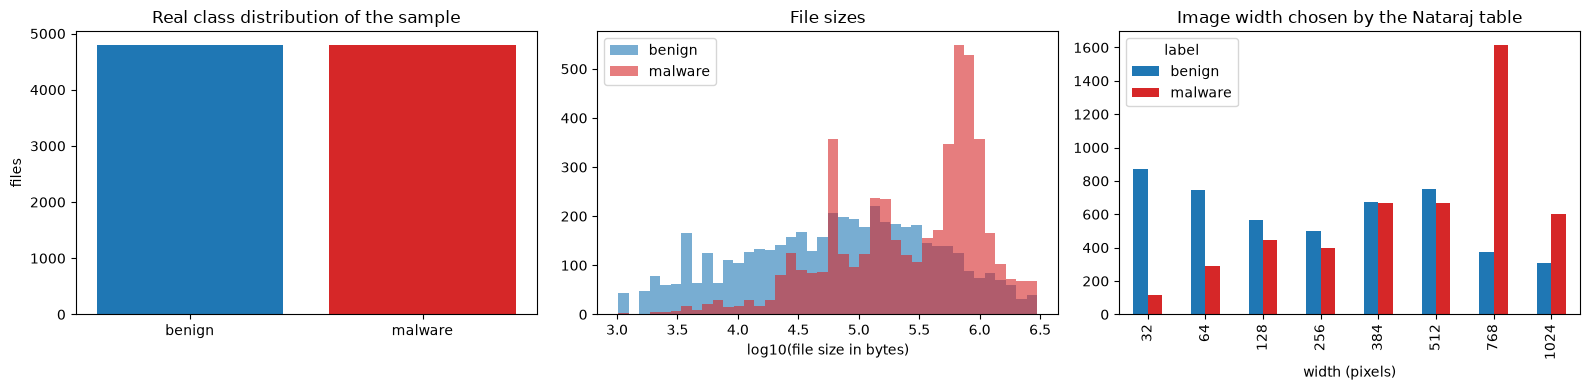

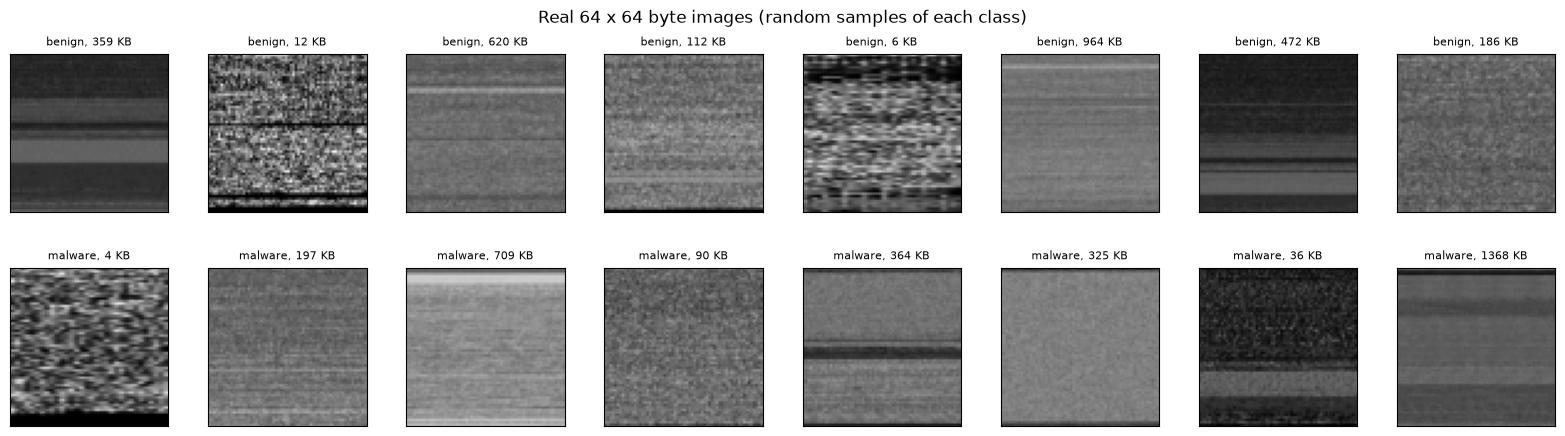

In [5]:
# Basic facts about the real data
pix_names = [f"pixel_{r:02d}_{c:02d}" for r in range(IMG_SIDE) for c in range(IMG_SIDE)]
X_PIX = IMGS.reshape(len(IMGS), -1).astype(np.float32) / 255.0      # 4096 features per file, scaled to [0, 1]
LABELS = {0: "benign", 1: "malware"}
print("dataset shape (files x features):", X_PIX.shape, "(each row is a 64 x 64 grayscale image of a file's bytes)")
print("feature names:", pix_names[:3], "...", pix_names[-2:], f"({len(pix_names)} features)")
print("original label values (folder names in the archives): data-benign/ -> 0 'benign', data/ -> 1 'malware'")
print(pd.Series(Y).map(LABELS).value_counts().to_string())
meta = pd.DataFrame({"label": pd.Series(Y).map(LABELS), "bytes": FSIZE, "image_width_px": FWIDTH})
print(meta.groupby("label")["bytes"].describe().round(0).to_string())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
cnt = meta["label"].value_counts().reindex(["benign", "malware"])
ax[0].bar(cnt.index, cnt.values, color=["tab:blue", "tab:red"]); ax[0].set_title("Real class distribution of the sample"); ax[0].set_ylabel("files")
for lab, col in [("benign", "tab:blue"), ("malware", "tab:red")]:
    ax[1].hist(np.log10(meta.loc[meta.label == lab, "bytes"]), bins=40, alpha=0.6, color=col, label=lab)
ax[1].set_xlabel("log10(file size in bytes)"); ax[1].set_title("File sizes"); ax[1].legend()
wc = pd.crosstab(meta["image_width_px"], meta["label"]); wc.plot(kind="bar", ax=ax[2], color=["tab:blue", "tab:red"]); ax[2].set_title("Image width chosen by the Nataraj table"); ax[2].set_xlabel("width (pixels)")
plt.tight_layout(); plt.show()

# A few real images per class
rng_vis = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for r, lab in enumerate([0, 1]):
    idx = rng_vis.choice(np.where(Y == lab)[0], 8, replace=False)
    for c, i in enumerate(idx):
        axes[r, c].imshow(IMGS[i], cmap="gray", vmin=0, vmax=255); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
        axes[r, c].set_title(f"{LABELS[lab]}, {FSIZE[i]/1024:.0f} KB", fontsize=8)
plt.suptitle("Real 64 x 64 byte images (random samples of each class)"); plt.tight_layout(); plt.subplots_adjust(hspace=0.35, top=0.88); plt.show()

training split 8000 files, test split 1600 files; PCA explained variance of the first 7 components: [0.426 0.099 0.069 0.035 0.027 0.022 0.016] sum 0.695


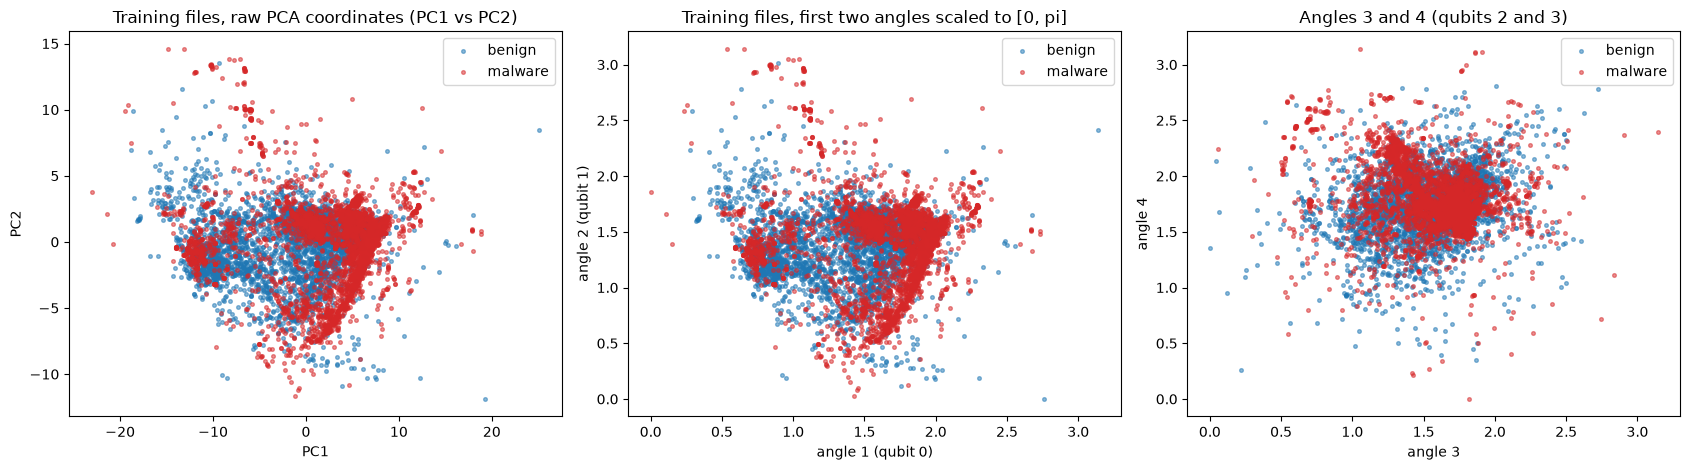

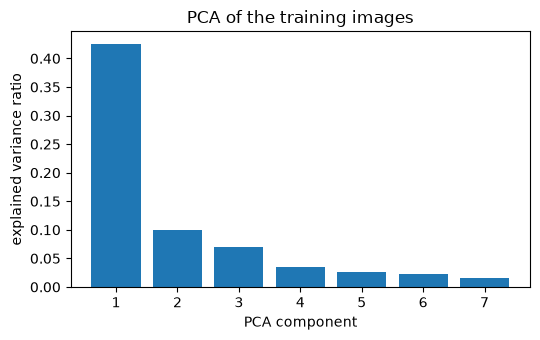

In [6]:
# Splits and preprocessing used by every experiment (all fitting on the training split only)
def split_indices(n_train, n_test, seed):
    """Balanced random subset of the pool, then a stratified split into n_train / n_test."""
    rng = np.random.default_rng(1000 * seed + n_train)
    per_class = (n_train + n_test) // 2
    sel = np.concatenate([rng.choice(np.where(Y == c)[0], per_class, replace=False) for c in (0, 1)])
    tr, te = train_test_split(sel, test_size=n_test, stratify=Y[sel], random_state=seed)
    return tr, te

def prepare(n_train, n_test, seed, nqs, X_all=None):
    """PCA (training split only, fitted once with max(nqs) components) and [0, pi] scaling per qubit count."""
    X_all = X_PIX if X_all is None else X_all
    tr, te = split_indices(n_train, n_test, seed)
    pca = PCA(n_components=min(max(nqs), len(tr) - 1), svd_solver="randomized", random_state=seed).fit(X_all[tr])
    Ztr, Zte = pca.transform(X_all[tr]), pca.transform(X_all[te])
    out = {"tr": tr, "te": te, "ytr": Y[tr], "yte": Y[te], "pca": pca, "Ztr": Ztr, "Zte": Zte, "angles": {}}
    for k in nqs:
        sc = MinMaxScaler((0, np.pi)).fit(Ztr[:, :k])                      # CHOICE: angles in [0, pi]
        out["angles"][k] = (sc.transform(Ztr[:, :k]), np.clip(sc.transform(Zte[:, :k]), 0, np.pi))
    return out

n_tr_vis, n_te_vis = SIZES[-1]
nq_vis = max(N_QUBITS_LIST)
D = prepare(n_tr_vis, n_te_vis, SEED, N_QUBITS_LIST)
print(f"training split {len(D['tr'])} files, test split {len(D['te'])} files; PCA explained variance of the first {nq_vis} components:",
      np.round(D["pca"].explained_variance_ratio_[:nq_vis], 3), "sum", round(float(D["pca"].explained_variance_ratio_[:nq_vis].sum()), 3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for lab, col in [(0, "tab:blue"), (1, "tab:red")]:
    m = D["ytr"] == lab
    ax[0].scatter(D["Ztr"][m, 0], D["Ztr"][m, 1], s=7, alpha=0.5, c=col, label=LABELS[lab])
ax[0].set_title("Training files, raw PCA coordinates (PC1 vs PC2)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend()
A_tr = D["angles"][nq_vis][0]
for lab, col in [(0, "tab:blue"), (1, "tab:red")]:
    m = D["ytr"] == lab
    ax[1].scatter(A_tr[m, 0], A_tr[m, 1], s=7, alpha=0.5, c=col, label=LABELS[lab])
ax[1].set_title("Training files, first two angles scaled to [0, pi]"); ax[1].set_xlabel("angle 1 (qubit 0)"); ax[1].set_ylabel("angle 2 (qubit 1)"); ax[1].legend()
for lab, col in [(0, "tab:blue"), (1, "tab:red")]:
    m = D["ytr"] == lab
    ax[2].scatter(A_tr[m, 2], A_tr[m, 3] if A_tr.shape[1] > 3 else A_tr[m, 2], s=7, alpha=0.5, c=col, label=LABELS[lab])
ax[2].set_title("Angles 3 and 4 (qubits 2 and 3)" if A_tr.shape[1] > 3 else "Angle 3 twice"); ax[2].set_xlabel("angle 3"); ax[2].set_ylabel("angle 4"); ax[2].legend()
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 1, figsize=(5.5, 3.5))
ax.bar(range(1, len(D["pca"].explained_variance_ratio_) + 1), D["pca"].explained_variance_ratio_); ax.set_xlabel("PCA component"); ax.set_ylabel("explained variance ratio"); ax.set_title("PCA of the training images")
plt.tight_layout(); plt.show()

## 3. Quantum feature maps and the fidelity kernel

The four feature maps are instances of Havlicek et al.'s Pauli feature map `U_phi(x) = exp(i sum_S phi_S(x) prod_{i in S} P_i)`, applied after a layer of Hadamard gates and repeated `reps = 2` times:

* **Z**: `P = Z` on single qubits only, `phi_i = x_i`; no entanglement, the state is a product state.
* **ZZ**: `Z` and `ZZ` terms, `phi_i = x_i`, `phi_ij = (pi - x_i)(pi - x_j)`.
* **Pauli**: here `Z`, `Y` and `ZZ` terms (a CHOICE, the paper does not list the Pauli strings).
* **ZZphi**: like ZZ but `phi_ij = sin(pi - x_i) sin(pi - x_j)`.

The kernel is `K_ij = |<phi(x_i)|phi(x_j)>|^2`, which a quantum computer estimates by running `U_phi(x_i)` followed by `U_phi(x_j)^dagger` and counting how often the all-zero string appears (`ComputeUncompute`). With 1000 shots every entry is a binomial estimate. The classical SVM then uses `K` as a precomputed kernel.

To simulate 20 experiments with up to 9600 states quickly we simulate the circuits exactly with vectorised NumPy and prove (section 4) that the states equal the ones of the real Qiskit circuits.

In [7]:
# ---- Exact vectorised simulation of the four Pauli feature maps (CHOICE: Pauli = Z, Y, ZZ) ----
def zz_phi_map(x):
    """ZZphi data map of the paper: x_i on single qubits, sin(pi-x_i) sin(pi-x_j) on pairs."""
    if len(x) == 1: return x[0]
    return functools.reduce(lambda m, n: m * n, np.sin(np.pi - np.asarray(x, dtype=object)))

FEATURE_MAPS = {"ZZ": (["Z", "ZZ"], None), "Pauli": (["Z", "Y", "ZZ"], None), "ZZphi": (["Z", "ZZ"], zz_phi_map), "Z": (["Z"], None)}

def build_circuit(name, n_qubits, reps=REPS, entanglement=ENTANGLEMENT):
    """The real Qiskit feature-map circuit (function-style circuit library)."""
    paulis, dmap = FEATURE_MAPS[name]
    kw = dict(feature_dimension=n_qubits, reps=reps, entanglement=entanglement, paulis=paulis)
    if dmap is not None: kw["data_map_func"] = dmap
    return pauli_feature_map(**kw)

def _pairs(n, ent):
    return list(itertools.combinations(range(n), 2)) if ent == "full" else [(i, i + 1) for i in range(n - 1)]

def _data_map(name, X, idx):
    if len(idx) == 1: return X[:, idx[0]]
    if name == "ZZphi": return np.prod([np.sin(np.pi - X[:, i]) for i in idx], axis=0)
    return np.prod([np.pi - X[:, i] for i in idx], axis=0)

_H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
def _apply_1q(psi, U, q, n):
    N = psi.shape[0]; t = psi.reshape((N,) + (2,) * n); ax = 1 + (n - 1 - q)       # Qiskit little-endian qubit order
    t = np.moveaxis(t, ax, 1); shp = t.shape; t = t.reshape(N, 2, -1)
    t = np.einsum("ab,nbk->nak", U, t) if U.ndim == 2 else np.einsum("nab,nbk->nak", U, t)
    return np.moveaxis(t.reshape(shp), 1, ax).reshape(N, -1)

def statevectors(name, X, reps=REPS, entanglement=ENTANGLEMENT):
    """Exact states of [U_phi(x) H^n]^reps |0^n> for every row of X (n_samples, n_qubits)."""
    paulis, _ = FEATURE_MAPS[name]; N, n = X.shape
    psi = np.zeros((N, 2 ** n), dtype=complex); psi[:, 0] = 1.0
    bits = (np.arange(2 ** n)[:, None] >> np.arange(n)[None, :]) & 1; z = 1 - 2 * bits
    for _ in range(reps):
        for q in range(n): psi = _apply_1q(psi, _H, q, n)
        for p in paulis:
            if len(p) == 1:
                for q in range(n):
                    phi = _data_map(name, X, [q])
                    if p == "Z": psi = psi * np.exp(1j * phi[:, None] * z[None, :, q])
                    elif p == "Y":
                        Y_ = np.array([[0, -1j], [1j, 0]])
                        U = np.cos(phi)[:, None, None] * np.eye(2) - 1j * np.sin(phi)[:, None, None] * Y_
                        psi = _apply_1q(psi, U, q, n)
            else:
                for (i, j) in _pairs(n, entanglement):
                    psi = psi * np.exp(1j * _data_map(name, X, [i, j])[:, None] * (z[None, :, i] * z[None, :, j]))
    return psi.conj()          # conjugate so that the states equal Qiskit's up to a global phase

def kernel_matrix(SA, SB, shots, rng, symmetric, chunk=1000):
    """K_ij = Binomial(shots, |<a_i|b_j>|^2)/shots (shots=None: exact). Symmetric case: upper triangle sampled, diagonal 1, like Qiskit."""
    nA, nB = len(SA), len(SB); K = np.empty((nA, nB), dtype=np.float64); SBt = SB.T
    for i in range(0, nA, chunk):
        P = np.abs(SA[i:i + chunk].conj() @ SBt) ** 2
        if shots is not None: P = rng.binomial(shots, np.clip(P, 0, 1)) / shots
        K[i:i + chunk] = P
    if symmetric:
        K = np.triu(K, 1); K = K + K.T; np.fill_diagonal(K, 1.0)
    return K

## 4. Quantum Circuit Architecture

We draw the circuits that define the four kernels exactly as Qiskit builds them (`pauli_feature_map`, 4 qubits, `reps = 2`, full entanglement; the circuits are flat and made of `h`, `p`, `cx`, `sx` gates), the complete fidelity circuit that `ComputeUncompute` executes for one kernel entry (feature map of `x`, inverse feature map of `y`, measurement), and print qubit count, depth and number of trainable parameters. The kernel has **no trainable circuit parameters**: the only parameters are the n input angles; learning happens in the classical SVM. The notebook then asserts that the NumPy simulator used for all experiments reproduces these circuits.

feature map  qubits  depth                                           gates  input parameters  trainable parameters
         ZZ       4     31                     {'cx': 24, 'p': 20, 'h': 8}                 4                     0
      Pauli       4     37 {'p': 28, 'cx': 24, 'h': 8, 'sx': 8, 'sxdg': 8}                 4                     0
      ZZphi       4     31                     {'cx': 24, 'p': 20, 'h': 8}                 4                     0
          Z       4      4                                {'h': 8, 'p': 8}                 4                     0


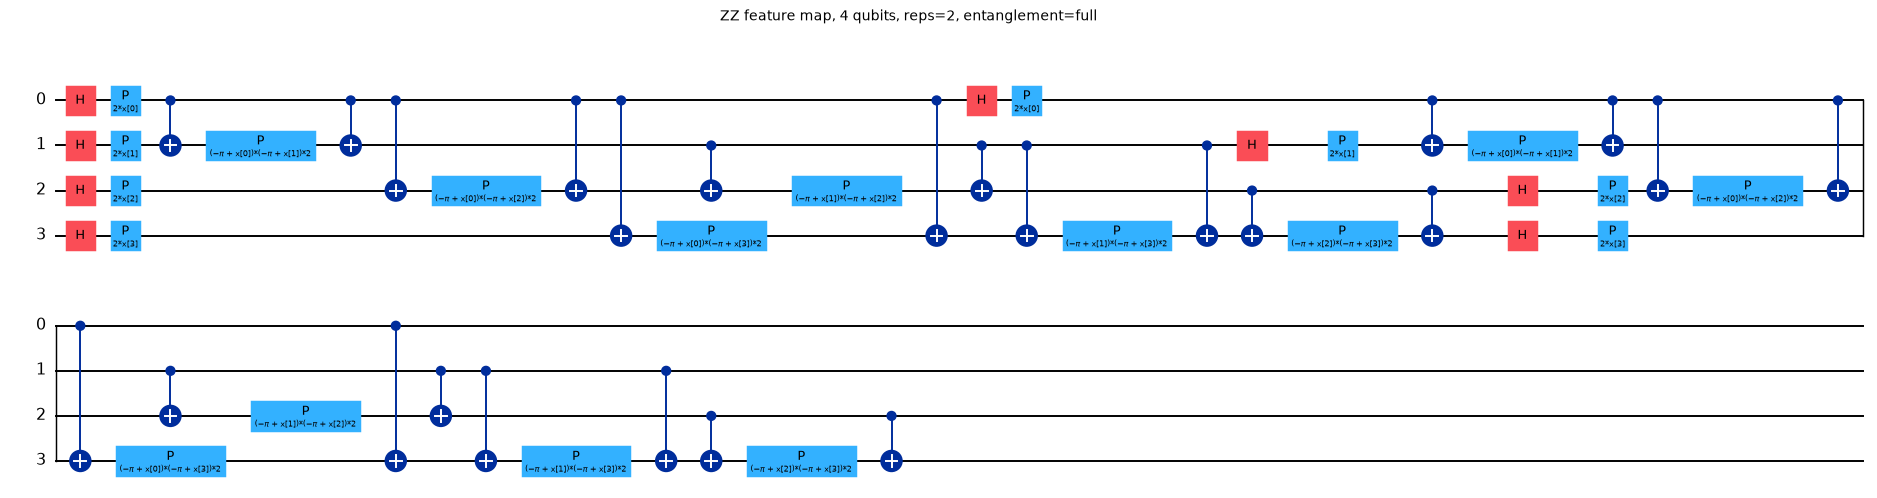

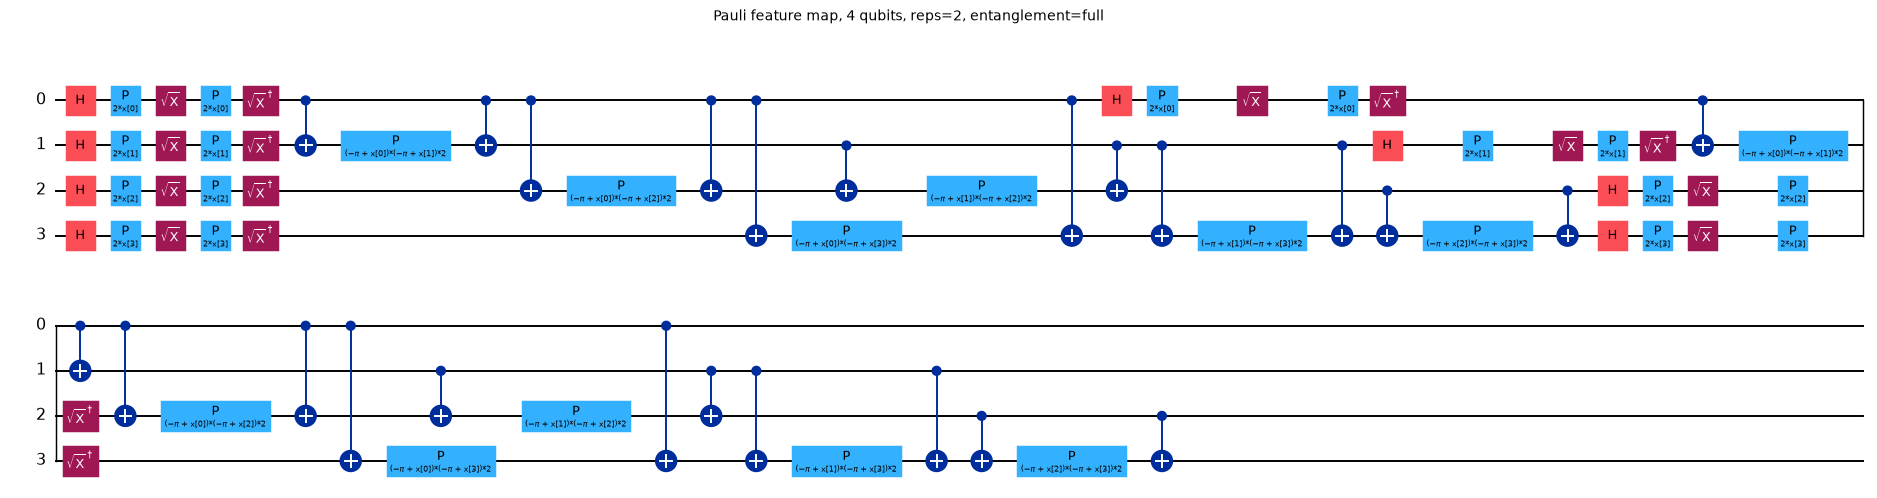

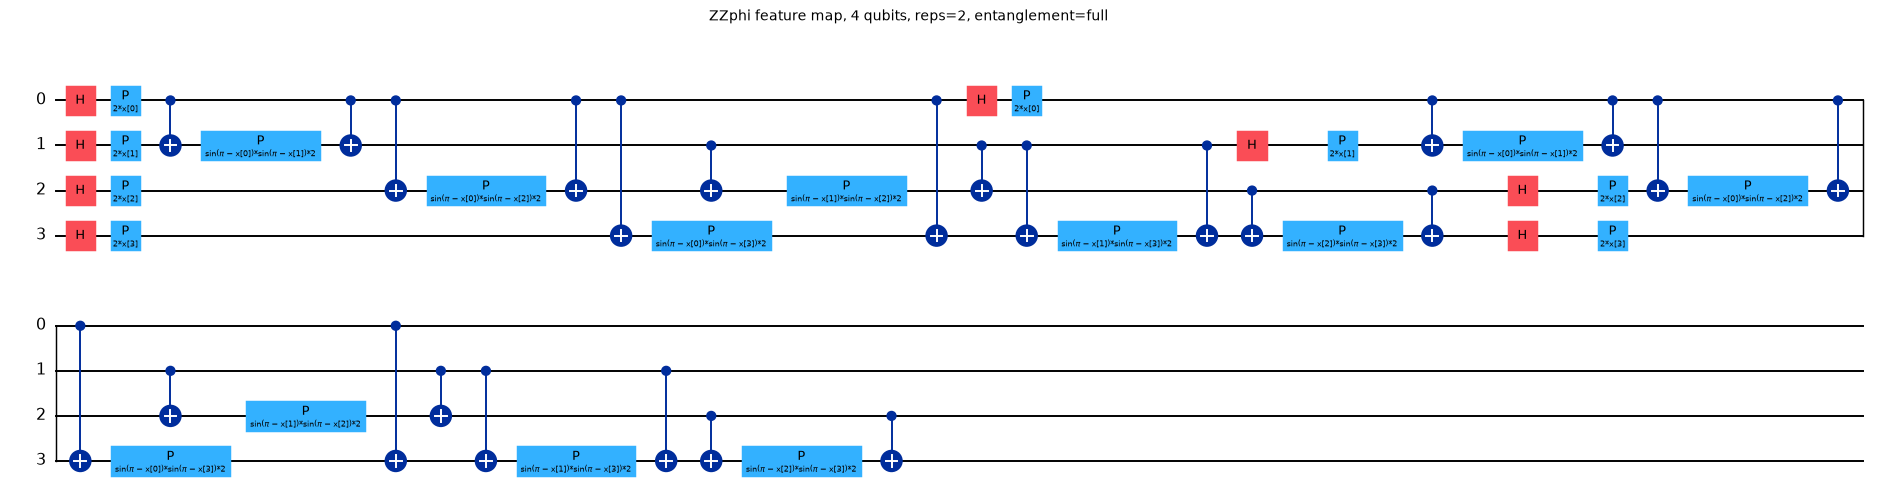

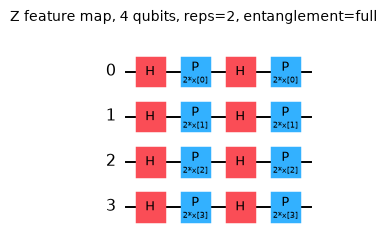

In [8]:
rows = []
for name in QUANTUM_MAPS:
    qc = build_circuit(name, 4)
    rows.append({"feature map": name, "qubits": qc.num_qubits, "depth": qc.depth(), "gates": dict(qc.count_ops()),
                 "input parameters": qc.num_parameters, "trainable parameters": 0})
print(pd.DataFrame(rows).to_string(index=False))
for name in QUANTUM_MAPS:
    qc = build_circuit(name, 4)
    fig = qc.draw("mpl", fold=40, scale=0.7)
    fig.suptitle(f"{name} feature map, 4 qubits, reps={REPS}, entanglement={ENTANGLEMENT}", fontsize=10)
    display(fig)

fidelity circuit (ZZ map, 3 qubits): qubits 3 | depth 45 | trainable parameters 0 (the 6 angles are the data x and y)


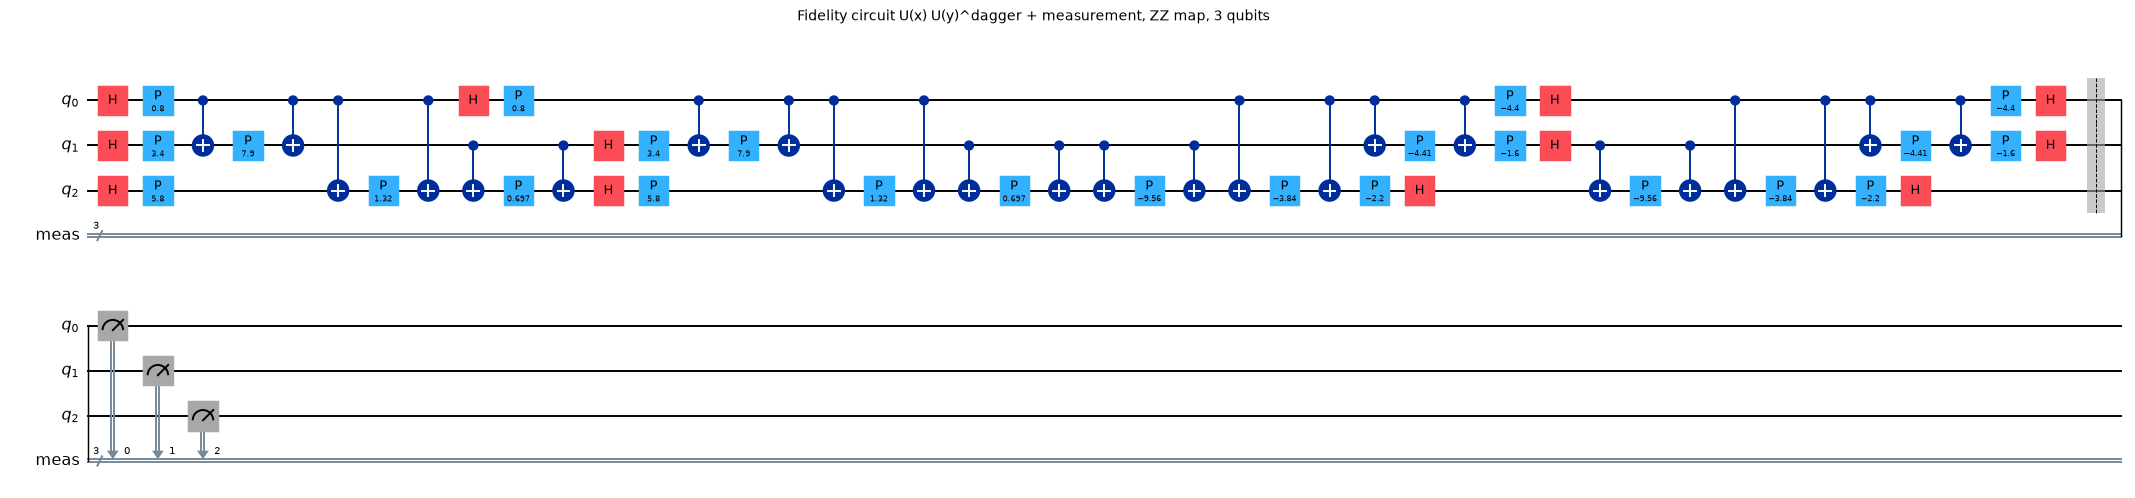

probability of the all-zero outcome (kernel value): 0.087085


In [9]:
# The circuit actually executed for one kernel entry: U(x) then U(y)^dagger, then measurement (what ComputeUncompute builds)
fm = build_circuit("ZZ", 3)
x_demo, y_demo = np.array([0.4, 1.7, 2.9]), np.array([2.2, 0.8, 1.1])
fid = QuantumCircuit(3)
fid.compose(fm.assign_parameters(x_demo), inplace=True)
fid.compose(fm.assign_parameters(y_demo).inverse(), inplace=True)
fid.measure_all()
print("fidelity circuit (ZZ map, 3 qubits): qubits", fid.num_qubits, "| depth", fid.depth(), "| trainable parameters 0 (the 6 angles are the data x and y)")
fig = fid.draw("mpl", fold=45, scale=0.7); fig.suptitle("Fidelity circuit U(x) U(y)^dagger + measurement, ZZ map, 3 qubits", fontsize=10); display(fig)
p0 = Statevector(fid.remove_final_measurements(inplace=False)).probabilities()[0]
print("probability of the all-zero outcome (kernel value):", round(float(p0), 6))

In [10]:
# Equivalence assertion: NumPy exact simulator == Qiskit circuits (states up to global phase, hence kernels equal)
rng_chk = np.random.default_rng(SEED)
for n in [3, 4, 6, 7]:
    Xc = rng_chk.uniform(0, np.pi, (5, n))
    for name in QUANTUM_MAPS:
        qc = build_circuit(name, n)
        S_q = np.array([Statevector(qc.assign_parameters(dict(zip(qc.parameters, xi)))).data for xi in Xc])
        S_n = statevectors(name, Xc)
        overlap = np.abs(np.einsum("ij,ij->i", S_q.conj(), S_n))
        assert np.allclose(overlap, 1.0, atol=1e-9), (n, name, overlap)
        K_q = np.abs(S_q.conj() @ S_q.T) ** 2; K_n = np.abs(S_n.conj() @ S_n.T) ** 2
        assert np.allclose(K_q, K_n, atol=1e-9)
print("OK: for 3, 4, 6, 7 qubits and the four maps the NumPy states equal the Qiskit circuit states (|overlap| = 1) and the kernels agree to 1e-9.")

OK: for 3, 4, 6, 7 qubits and the four maps the NumPy states equal the Qiskit circuit states (|overlap| = 1) and the kernels agree to 1e-9.


## 5. Shot noise: the 1000-shot kernel versus Qiskit's sampler

A quantum computer (or a shot-based simulator) returns each kernel entry as a count of the all-zero outcome out of 1000 shots. We emulate this with a binomial draw. As a check, we compute the kernel of 12 samples with Qiskit's own `FidelityQuantumKernel` (a `ComputeUncompute` fidelity on a `StatevectorSampler` with 1000 shots) and compare its error distribution (over ten independent kernels) with the one of our emulation. We also check that Qiskit's exact `FidelityStatevectorKernel` plus `QSVC` equals our precomputed-kernel `SVC` (the same classifier).

How to read the output: the standard deviation of the error (about 0.010 to 0.011 per entry) is what matters and it agrees with theory for both. The printed mean error of Qiskit's sampler in this ten-seed check (about +0.005) is not a systematic bias: Qiskit's sampler reuses its seed for every circuit of one kernel, so the errors of one kernel are correlated; in a separate check with 40 other seeds on other data the mean error was -0.001.

In [11]:
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.kernels import FidelityQuantumKernel, FidelityStatevectorKernel
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.algorithms import QSVC

chk = prepare(200, 40, SEED, [3])
A_tr, A_te = chk["angles"][3]; Xs = A_tr[:12]
fm3 = build_circuit("ZZ", 3)
S = statevectors("ZZ", Xs); K_exact = kernel_matrix(S, S, None, None, True)
K_fid_exact = FidelityStatevectorKernel(feature_map=fm3).evaluate(Xs)
print("exact: max |NumPy - FidelityStatevectorKernel| (rounding level) =", float(np.abs(K_exact - K_fid_exact).max()))
assert np.allclose(K_exact, K_fid_exact, atol=1e-5)   # Qiskit's statevector kernel works with single-precision-level rounding (differences ~1e-7)

iu = np.triu_indices(12, 1)
e_q, e_e = [], []
for i in range(10):       # ten independent 1000-shot kernels from Qiskit's sampler and from the binomial emulation
    samp = StatevectorSampler(default_shots=SHOTS, seed=SEED + i)
    K_qiskit = FidelityQuantumKernel(feature_map=fm3, fidelity=ComputeUncompute(sampler=samp)).evaluate(Xs)
    K_emul = kernel_matrix(S, S, SHOTS, np.random.default_rng(SEED + i), True)
    e_q.append(K_qiskit[iu] - K_exact[iu]); e_e.append(K_emul[iu] - K_exact[iu])
e_q, e_e = np.concatenate(e_q), np.concatenate(e_e)
theory = np.sqrt(np.mean(K_exact[iu] * (1 - K_exact[iu])) / SHOTS)
print(f"1000-shot error std over 10 kernels: Qiskit sampler {e_q.std():.4f} | binomial emulation {e_e.std():.4f} | theory sqrt(mean p(1-p)/1000) = {theory:.4f}")
print(f"mean error (bias): Qiskit {e_q.mean():+.5f} | emulation {e_e.mean():+.5f}")
assert abs(e_q.std() - e_e.std()) < 0.15 * e_e.std()

# QSVC (Qiskit) == SVC with precomputed kernel, exact kernel, on a small problem
n_small = 80
Atr_s, ytr_s, Ate_s, yte_s = A_tr[:n_small], chk["ytr"][:n_small], A_te, chk["yte"]
qsvc = QSVC(quantum_kernel=FidelityStatevectorKernel(feature_map=fm3)).fit(Atr_s, ytr_s)
S_tr, S_te = statevectors("ZZ", Atr_s), statevectors("ZZ", Ate_s)
svc = SVC(kernel="precomputed").fit(kernel_matrix(S_tr, S_tr, None, None, True), ytr_s)
p1 = qsvc.predict(Ate_s); p2 = svc.predict(kernel_matrix(S_te, S_tr, None, None, False))
print("QSVC vs precomputed SVC predictions identical:", bool((p1 == p2).all()), "| accuracy", round(accuracy_score(yte_s, p1), 3))
assert (p1 == p2).all()

exact: max |NumPy - FidelityStatevectorKernel| (rounding level) = 4.0086501026936894e-07


1000-shot error std over 10 kernels: Qiskit sampler 0.0102 | binomial emulation 0.0105 | theory sqrt(mean p(1-p)/1000) = 0.0110
mean error (bias): Qiskit +0.00490 | emulation +0.00006


QSVC vs precomputed SVC predictions identical: True | accuracy 0.7


## 6. The simulator experiments (Tables 1 and 2)

For each training size, each number of qubits and each random draw of a balanced subset, the notebook (i) fits PCA on the training images, (ii) scales to [0, pi], (iii) computes the four quantum kernels with 1000-shot sampling noise (training matrix symmetric, test matrix rectangular) and trains `SVC(kernel="precomputed")`, (iv) trains SVMs with the four classical kernels on the same angles, (v) records accuracy and F1 (malware positive), and (vi) records a random forest as an extra baseline. Quantum kernels with the exact (infinite-shot) matrix are also computed for the largest qubit count to show what the shot noise costs.

In [12]:
RESULTS = []          # one row per (train size, seed, qubits, kernel)
PREDS = {}            # predictions kept for the confusion matrices
def record(n_train, seed, nq, kernel, yte, pred, secs, kind):
    RESULTS.append(dict(n_train=n_train, seed=seed, qubits=nq, kernel=kernel, kind=kind, acc=accuracy_score(yte, pred),
                        f1=f1_score(yte, pred, pos_label=1, zero_division=0), secs=secs))

t_all = time.time()
for (n_tr, n_te) in SIZES:
    t_size = time.time()
    for s in range(SEEDS_BY_TRAIN[n_tr]):
        seed = SEED + s
        P_ = prepare(n_tr, n_te, seed, QUBITS_BY_TRAIN[n_tr])
        ytr, yte = P_["ytr"], P_["yte"]
        for nq in QUBITS_BY_TRAIN[n_tr]:
            Atr, Ate = P_["angles"][nq]
            for name in QUANTUM_MAPS:
                rng = np.random.default_rng([SEED, seed, n_tr, nq, QUANTUM_MAPS.index(name)])
                t0 = time.time()
                Str, Ste = statevectors(name, Atr), statevectors(name, Ate)
                Ktr = kernel_matrix(Str, Str, SHOTS, rng, True); Kte = kernel_matrix(Ste, Str, SHOTS, rng, False)
                clf = SVC(kernel="precomputed", cache_size=1500).fit(Ktr, ytr); pred = clf.predict(Kte)
                record(n_tr, seed, nq, name, yte, pred, time.time() - t0, "quantum")
                if nq == max(N_QUBITS_LIST) and seed == SEED:
                    PREDS[(n_tr, nq, name)] = (yte, pred)
                    Ktr_e = kernel_matrix(Str, Str, None, None, True); Kte_e = kernel_matrix(Ste, Str, None, None, False)
                    pred_e = SVC(kernel="precomputed", cache_size=1500).fit(Ktr_e, ytr).predict(Kte_e)
                    record(n_tr, seed, nq, name, yte, pred_e, 0.0, "quantum_exact")
                del Ktr, Kte
            for kern in CLASSICAL_KERNELS:
                t0 = time.time(); clf = SVC(kernel=kern, cache_size=1500).fit(Atr, ytr); pred = clf.predict(Ate)
                record(n_tr, seed, nq, kern, yte, pred, time.time() - t0, "classical")
                if nq == max(N_QUBITS_LIST) and seed == SEED: PREDS[(n_tr, nq, kern)] = (yte, pred)
            t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1).fit(Atr, ytr)
            record(n_tr, seed, nq, "RandomForest", yte, rf.predict(Ate), time.time() - t0, "classical")
    print(f"train/test {n_tr}/{n_te}: {SEEDS_BY_TRAIN[n_tr]} draws done in {time.time() - t_size:.0f}s (total {time.time() - t_all:.0f}s)", flush=True)
R = pd.DataFrame(RESULTS); print("rows:", len(R))

train/test 500/100: 5 draws done in 176s (total 176s)


train/test 1000/200: 5 draws done in 342s (total 518s)


train/test 2000/400: 3 draws done in 971s (total 1489s)


train/test 4000/800: 1 draws done in 382s (total 1871s)


train/test 8000/1600: 1 draws done in 1811s (total 3682s)


rows: 524


In [13]:
ORDER = QUANTUM_MAPS + CLASSICAL_KERNELS
def table(metric):
    g = R[R.kind.isin(["quantum", "classical"]) & R.kernel.isin(ORDER)].groupby(["n_train", "qubits", "kernel"])[metric]
    mean, std = g.mean().unstack("kernel")[ORDER], g.std().unstack("kernel")[ORDER].fillna(0)
    return mean, std
acc_mean, acc_std = table("acc"); f1_mean, f1_std = table("f1")
pd.set_option("display.width", 200)
print("Table 1 (re-computed): accuracy, mean over draws (std in the next table). Columns: quantum ZZ Pauli ZZphi Z | classical linear poly rbf sigmoid")
print(acc_mean.round(3).to_string())
print("\nstd over random draws (0 where a single draw was run):")
print(acc_std.round(3).to_string())
print("\nTable 2 (re-computed): F1 score, mean")
print(f1_mean.round(3).to_string())

Table 1 (re-computed): accuracy, mean over draws (std in the next table). Columns: quantum ZZ Pauli ZZphi Z | classical linear poly rbf sigmoid
kernel             ZZ  Pauli  ZZphi      Z  linear   poly    rbf  sigmoid
n_train qubits                                                           
500     3       0.726  0.718  0.764  0.722   0.622  0.718  0.758    0.498
        4       0.734  0.706  0.780  0.756   0.624  0.766  0.792    0.500
        6       0.726  0.724  0.790  0.790   0.644  0.782  0.794    0.498
        7       0.710  0.702  0.788  0.772   0.650  0.760  0.764    0.500
1000    3       0.746  0.731  0.778  0.707   0.600  0.772  0.776    0.500
        4       0.750  0.751  0.763  0.721   0.626  0.765  0.766    0.505
        6       0.753  0.742  0.792  0.771   0.639  0.755  0.773    0.497
        7       0.761  0.756  0.791  0.755   0.647  0.760  0.772    0.493
2000    3       0.741  0.726  0.765  0.712   0.595  0.745  0.772    0.501
        4       0.763  0.754  0.770  0.727

### Paper numbers and side-by-side comparison

The next cell types in the paper's Tables 1 and 2 (rows: training size / qubits; columns: ZZ, Pauli, ZZphi, Z, Linear, Polynomial, RBF, Sigmoid) and Table 3.

In [14]:
COLS = ORDER
def _tab(txt):
    d = {}
    for line in txt.strip().splitlines():
        a = line.split(); d[(int(a[0]), int(a[1]))] = [float(v) for v in a[2:]]
    return pd.DataFrame(d, index=COLS).T.rename_axis(["n_train", "qubits"])
PAPER_ACC = _tab('''
500 3 0.740 0.790 0.800 0.780 0.750 0.690 0.760 0.510
500 4 0.730 0.780 0.800 0.790 0.740 0.720 0.790 0.540
500 6 0.660 0.720 0.810 0.810 0.740 0.740 0.810 0.560
500 7 0.700 0.800 0.820 0.830 0.740 0.750 0.850 0.620
1000 3 0.725 0.675 0.735 0.720 0.705 0.730 0.745 0.575
1000 4 0.730 0.660 0.735 0.735 0.705 0.720 0.740 0.580
1000 6 0.745 0.760 0.780 0.775 0.735 0.745 0.790 0.640
1000 7 0.790 0.735 0.780 0.780 0.730 0.775 0.780 0.640
2000 3 0.710 0.730 0.748 0.757 0.718 0.672 0.770 0.603
2000 4 0.748 0.743 0.775 0.767 0.718 0.685 0.765 0.585
2000 6 0.777 0.728 0.770 0.780 0.740 0.735 0.782 0.595
2000 7 0.782 0.767 0.802 0.780 0.743 0.743 0.795 0.583
4000 3 0.799 0.784 0.771 0.777 0.766 0.639 0.787 0.671
4000 4 0.806 0.821 0.771 0.775 0.771 0.637 0.791 0.637
4000 6 0.830 0.812 0.816 0.800 0.772 0.804 0.830 0.608
4000 7 0.838 0.805 0.824 0.821 0.771 0.791 0.840 0.616
8000 3 0.783 0.779 0.797 0.796 0.779 0.619 0.804 0.633
8000 4 0.812 0.792 0.804 0.806 0.781 0.662 0.822 0.630
8000 6 0.835 0.806 0.819 0.818 0.779 0.734 0.840 0.616
8000 7 0.851 0.812 0.831 0.821 0.776 0.746 0.845 0.608
''')
PAPER_F1 = _tab('''
500 3 0.736 0.790 0.797 0.777 0.746 0.662 0.754 0.510
500 4 0.729 0.779 0.797 0.788 0.736 0.700 0.787 0.540
500 6 0.649 0.716 0.808 0.810 0.736 0.729 0.808 0.560
500 7 0.690 0.795 0.819 0.829 0.736 0.738 0.849 0.620
1000 3 0.723 0.675 0.732 0.717 0.700 0.728 0.742 0.574
1000 4 0.729 0.658 0.732 0.731 0.700 0.719 0.737 0.579
1000 6 0.744 0.756 0.779 0.775 0.730 0.738 0.789 0.640
1000 7 0.787 0.731 0.779 0.780 0.725 0.771 0.779 0.640
2000 3 0.707 0.728 0.747 0.756 0.716 0.651 0.769 0.601
2000 4 0.746 0.741 0.774 0.767 0.716 0.670 0.764 0.584
2000 6 0.776 0.726 0.769 0.780 0.739 0.729 0.782 0.595
2000 7 0.781 0.764 0.802 0.780 0.742 0.737 0.795 0.582
4000 3 0.797 0.783 0.769 0.775 0.764 0.612 0.786 0.671
4000 4 0.805 0.821 0.770 0.773 0.769 0.621 0.790 0.637
4000 6 0.830 0.811 0.816 0.799 0.771 0.803 0.830 0.607
4000 7 0.837 0.803 0.823 0.821 0.769 0.790 0.840 0.616
8000 3 0.783 0.779 0.796 0.794 0.778 0.589 0.804 0.633
8000 4 0.812 0.792 0.803 0.805 0.779 0.646 0.822 0.630
8000 6 0.835 0.806 0.818 0.818 0.778 0.731 0.840 0.616
8000 7 0.851 0.812 0.830 0.821 0.775 0.743 0.845 0.607
''')
PAPER_HW = pd.DataFrame([("4/2", "ibm_torino", 0.5, 0.333), ("4/2", "ibm_algiers", 0.5, 0.333), ("8/4", "ibm_torino", 1.0, 1.0),
                         ("8/4", "ibm_algiers", 0.75, 0.733), ("20/10", "ibm_cairo", 0.6, 0.6), ("20/10", "ibm_kyoto", 0.6, 0.524)],
                        columns=["train/test", "device", "paper accuracy", "paper F1"])
idx = acc_mean.index
diff = (acc_mean - PAPER_ACC.loc[idx]).round(3)
print("Notebook minus paper, accuracy (positive = this notebook is higher). Only the configurations that were run:")
print(diff.to_string())
tol = 0.02
within = (diff.abs() <= tol)
print("\nShare of cells within 2 accuracy points of the paper, per kernel:")
print(within.mean().round(2).to_string())
print("Mean absolute difference per kernel:"); print(diff.abs().mean().round(3).to_string())

Notebook minus paper, accuracy (positive = this notebook is higher). Only the configurations that were run:
kernel             ZZ  Pauli  ZZphi      Z  linear   poly    rbf  sigmoid
n_train qubits                                                           
500     3      -0.014 -0.072 -0.036 -0.058  -0.128  0.028 -0.002   -0.012
        4       0.004 -0.074 -0.020 -0.034  -0.116  0.046  0.002   -0.040
        6       0.066  0.004 -0.020 -0.020  -0.096  0.042 -0.016   -0.062
        7       0.010 -0.098 -0.032 -0.058  -0.090  0.010 -0.086   -0.120
1000    3       0.021  0.056  0.043 -0.013  -0.105  0.042  0.031   -0.075
        4       0.020  0.091  0.028 -0.014  -0.079  0.045  0.026   -0.075
        6       0.008 -0.018  0.012 -0.004  -0.096  0.010 -0.017   -0.143
        7      -0.029  0.021  0.011 -0.025  -0.083 -0.015 -0.008   -0.147
2000    3       0.031 -0.004  0.017 -0.045  -0.123  0.073  0.002   -0.102
        4       0.015  0.011 -0.005 -0.040  -0.122  0.068  0.022   -0.085
    

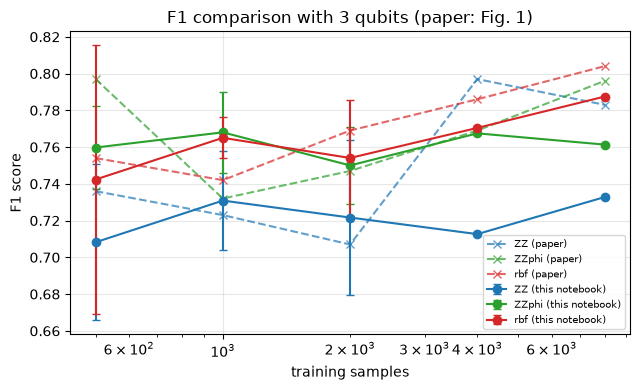

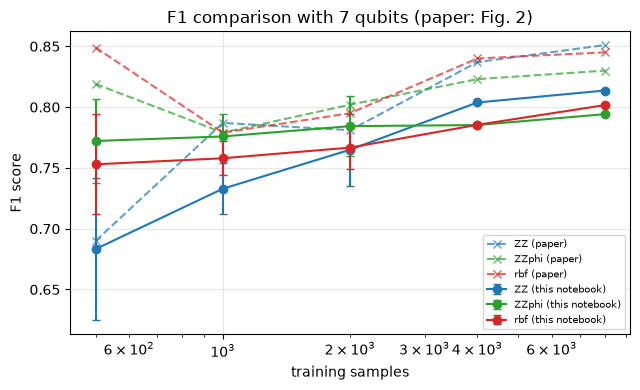

In [15]:
# Figures 1 and 2 of the paper (F1 of ZZ, ZZphi and RBF vs training size), paper dashed, this notebook solid
for nq in [min(N_QUBITS_LIST), max(N_QUBITS_LIST)]:
    fig, ax = plt.subplots(1, 1, figsize=(6.5, 4))
    for k, c in [("ZZ", "tab:blue"), ("ZZphi", "tab:green"), ("rbf", "tab:red")]:
        xs = [n for (n, q) in f1_mean.index if q == nq]
        ax.errorbar(xs, [f1_mean.loc[(n, nq), k] for n in xs], yerr=[f1_std.loc[(n, nq), k] for n in xs], c=c, marker="o", label=f"{k} (this notebook)", capsize=3)
        ax.plot(xs, [PAPER_F1.loc[(n, nq), k] for n in xs], c=c, ls="--", marker="x", alpha=0.7, label=f"{k} (paper)")
    ax.set_xscale("log"); ax.set_xlabel("training samples"); ax.set_ylabel("F1 score"); ax.set_title(f"F1 comparison with {nq} qubits (paper: Fig. {1 if nq == 3 else 2})"); ax.legend(fontsize=7); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

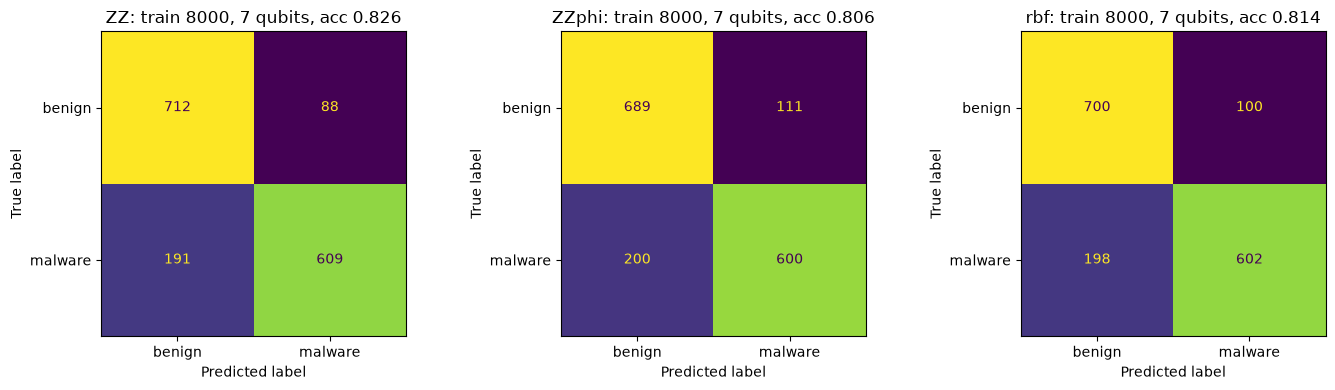

Accuracy with the exact (infinite-shot) quantum kernel vs 1000 shots, seed 42 , max qubits:
                exact                      1000 shots                     
kernel             ZZ  Pauli  ZZphi      Z         ZZ  Pauli  ZZphi      Z
n_train qubits                                                            
500     7       0.710  0.670  0.780  0.780      0.710  0.680  0.740  0.750
1000    7       0.795  0.760  0.825  0.780      0.785  0.770  0.810  0.770
2000    7       0.808  0.805  0.820  0.805      0.808  0.800  0.822  0.760
4000    7       0.812  0.812  0.801  0.785      0.819  0.812  0.796  0.770
8000    7       0.837  0.824  0.830  0.809      0.826  0.824  0.806  0.786

Random forest on the same PCA angles (accuracy):
qubits       3      4      6      7
n_train                            
500      0.764  0.776  0.780  0.774
1000     0.783  0.810  0.807  0.814
2000     0.795  0.818  0.818  0.812
4000     0.801    NaN    NaN  0.846
8000     0.834    NaN    NaN  0.867

Mean 

In [16]:
# Confusion matrices (malware = positive class) for the largest run: best quantum kernel vs RBF
n_big, nq_big = SIZES[-1][0], max(N_QUBITS_LIST)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, k in zip(axes, ["ZZ", "ZZphi", "rbf"]):
    yte_, pred_ = PREDS[(n_big, nq_big, k)]
    ConfusionMatrixDisplay(confusion_matrix(yte_, pred_, labels=[0, 1]), display_labels=["benign", "malware"]).plot(ax=ax, colorbar=False)
    ax.set_title(f"{k}: train {n_big}, {nq_big} qubits, acc {accuracy_score(yte_, pred_):.3f}")
plt.tight_layout(); plt.show()

# Extra rows: shot noise cost, random-forest baseline, wall-clock time
ex = R[R.kind == "quantum_exact"].groupby(["n_train", "qubits", "kernel"])["acc"].mean().unstack("kernel")
sh = R[(R.kind == "quantum") & (R.seed == SEED) & (R.qubits == max(N_QUBITS_LIST))].groupby(["n_train", "qubits", "kernel"])["acc"].mean().unstack("kernel")
print("Accuracy with the exact (infinite-shot) quantum kernel vs 1000 shots, seed", SEED, ", max qubits:")
print(pd.concat({"exact": ex[QUANTUM_MAPS], "1000 shots": sh[QUANTUM_MAPS]}, axis=1).round(3).to_string())
rf = R[R.kernel == "RandomForest"].groupby(["n_train", "qubits"])["acc"].mean().unstack("qubits")
print("\nRandom forest on the same PCA angles (accuracy):"); print(rf.round(3).to_string())
tm = R[R.kind.isin(["quantum", "classical"]) & R.kernel.isin(ORDER)].groupby(["n_train", "kind"])["secs"].mean().unstack("kind")
print("\nMean wall-clock seconds per (train + predict) fit:"); print(tm.round(2).to_string())

In [17]:
# Baselines with more information: SVC-RBF and random forest on all 4096 pixels (no PCA), second size (CPU time), one draw
tr, te = split_indices(*SIZES[1], SEED)
t0 = time.time(); svc_full = SVC(kernel="rbf").fit(X_PIX[tr], Y[tr]); a_svc = accuracy_score(Y[te], svc_full.predict(X_PIX[te]))
rf_full = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1).fit(X_PIX[tr], Y[tr]); a_rf = accuracy_score(Y[te], rf_full.predict(X_PIX[te]))
print(f"train/test {SIZES[1]}: all 4096 pixels  SVC-RBF acc {a_svc:.3f} | RandomForest acc {a_rf:.3f}  ({time.time()-t0:.0f}s)")
print("-> the 3-7 PCA components throw most of the information away; compare with the table above.")

train/test (1000, 200): all 4096 pixels  SVC-RBF acc 0.785 | RandomForest acc 0.825  (19s)
-> the 3-7 PCA components throw most of the information away; compare with the table above.


## 7. Validation-split tuning of the kernel bandwidth (extra, not in the paper)

The paper uses the angles as they are. A standard improvement for quantum kernels is a *bandwidth* (a scale `a` multiplying the angles). We choose `a` on a validation part of the training split only and report the test accuracy, so there is no test leakage.

In [18]:
n_b, nq_b = SIZES[0][0], max(N_QUBITS_LIST)
P_ = prepare(n_b, SIZES[0][1], SEED, [nq_b]); Atr, Ate = P_["angles"][nq_b]; ytr, yte = P_["ytr"], P_["yte"]
a_tr, a_val, y_tr2, y_val = train_test_split(Atr, ytr, test_size=0.25, stratify=ytr, random_state=SEED)
bw_rows = []
for name in ["ZZ", "ZZphi"]:
    best = None
    for a in [0.25, 0.5, 1.0, 2.0]:
        S1, S2 = statevectors(name, a * a_tr), statevectors(name, a * a_val)
        v = accuracy_score(y_val, SVC(kernel="precomputed").fit(kernel_matrix(S1, S1, None, None, True), y_tr2).predict(kernel_matrix(S2, S1, None, None, False)))
        bw_rows.append((name, a, round(v, 3)))
        if best is None or v > best[1]: best = (a, v)
    a = best[0]; S1, S2 = statevectors(name, a * Atr), statevectors(name, a * Ate)
    t_acc = accuracy_score(yte, SVC(kernel="precomputed").fit(kernel_matrix(S1, S1, None, None, True), ytr).predict(kernel_matrix(S2, S1, None, None, False)))
    print(f"{name}: validation accuracy per scale {[r[1:] for r in bw_rows if r[0]==name]} -> chosen a={a}, test accuracy {t_acc:.3f} (a=1 with 1000 shots, from the table of section 6, mean over draws: {acc_mean.loc[(n_b, nq_b), name]:.3f})")

ZZ: validation accuracy per scale [(0.25, 0.768), (0.5, 0.784), (1.0, 0.768), (2.0, 0.784)] -> chosen a=0.5, test accuracy 0.720 (a=1 with 1000 shots, from the table of section 6, mean over draws: 0.710)


ZZphi: validation accuracy per scale [(0.25, 0.768), (0.5, 0.768), (1.0, 0.784), (2.0, 0.76)] -> chosen a=1.0, test accuracy 0.780 (a=1 with 1000 shots, from the table of section 6, mean over draws: 0.788)


### 7b. Sensitivity to the image construction (extra)

The paper says the images were "resized to a uniform size while maintaining their aspect ratio", which can be read in two ways: stretch the image to 64 x 64 (`stretch`, the main choice of this notebook) or scale the longer side to 64 pixels and zero-pad (`keep_aspect`, our first reading). We first implemented `keep_aspect`, found accuracies far below the paper, and compared the two readings; the result below is why `stretch` is the main variant. Both variants of every image are cached; the comparison uses the second training size, the largest qubit count and the same random draws, so the choice was made on training-size-1000 test accuracy, which is a mild form of tuning to the paper and is disclosed here.

In [19]:
n_s, t_s = SIZES[1]; nq_s = max(N_QUBITS_LIST); sens = []
for mode, IM in [("keep_aspect", IMGS_KA), ("stretch", IMGS_ST)]:
    Xm = IM.reshape(len(IM), -1).astype(np.float32) / 255.0
    for s in range(SEEDS_BY_TRAIN[n_s]):
        seed = SEED + s
        P_ = prepare(n_s, t_s, seed, [nq_s], X_all=Xm); Atr, Ate = P_["angles"][nq_s]; ytr, yte = P_["ytr"], P_["yte"]
        for name in ["ZZ", "ZZphi"]:
            rng = np.random.default_rng([SEED, seed, 7, QUANTUM_MAPS.index(name)])
            Str, Ste = statevectors(name, Atr), statevectors(name, Ate)
            pred = SVC(kernel="precomputed").fit(kernel_matrix(Str, Str, SHOTS, rng, True), ytr).predict(kernel_matrix(Ste, Str, SHOTS, rng, False))
            sens.append((mode, name, accuracy_score(yte, pred)))
        for kern in ["linear", "rbf"]:
            sens.append((mode, kern, accuracy_score(yte, SVC(kernel=kern).fit(Atr, ytr).predict(Ate))))
S_ = pd.DataFrame(sens, columns=["image mode", "kernel", "acc"]).groupby(["image mode", "kernel"])["acc"].agg(["mean", "std"]).round(3)
print(f"train/test {n_s}/{t_s}, {nq_s} qubits, {SEEDS_BY_TRAIN[n_s]} draws:"); print(S_.to_string())

train/test 1000/200, 7 qubits, 5 draws:
                     mean    std
image mode  kernel              
keep_aspect ZZ      0.723  0.020
            ZZphi   0.780  0.022
            linear  0.648  0.029
            rbf     0.754  0.034
stretch     ZZ      0.766  0.016
            ZZphi   0.794  0.018
            linear  0.647  0.045
            rbf     0.772  0.014


## 8. Emulating the IBM Quantum runs (Table 3) with device noise models

The paper's hardware experiments (4/2, 8/4, 20/10 samples) cannot be repeated here without access to the IBM devices. We emulate them with Qiskit's *fake devices* (calibration snapshots of the same processors, noise model from `qiskit-ibm-runtime`) and the same pipeline as the paper: transpile every fidelity circuit to the device's native gate set (the first fix of the paper), compute each kernel entry as an independent circuit with 1000 shots (the second fix is not needed offline), and train the SVM on the precomputed kernel. `IBM_TOKEN` can be set above to run the identical function on a real backend, which is skipped otherwise. With 20/10 samples the test accuracy can only take 11 values and a difference of one sample is 10 points, so these numbers are indicative at best, exactly as the paper says.

In [20]:
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as AerSamplerV2
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
import qiskit_ibm_runtime.fake_provider as fake_provider

def make_pass_manager(backend, seed):
    """Preset pass manager that transpiles the fidelity circuits to the device's native gates and coupling map (the paper's fix 2).
    FakeCairoV2's target holds a CX that cannot be direction-flipped (Qiskit 2.5.2 raises TranspilerError), so for that one device the
    basis gates and the coupling map are passed instead of the backend object (same device, same noise model)."""
    if "cairo" in str(getattr(backend, "name", "")).lower():
        return generate_preset_pass_manager(optimization_level=1, basis_gates=list(backend.operation_names), coupling_map=backend.coupling_map, seed_transpiler=seed)
    return generate_preset_pass_manager(optimization_level=1, backend=backend, seed_transpiler=seed)

def hw_qsvm(backend, sampler, n_train, n_test, repeat, name="ZZ", nq=HW_QUBITS):
    """QSVM with the Qiskit FidelityQuantumKernel; fidelity circuits transpiled to `backend` (the paper's fix)."""
    seed = SEED + 100 * repeat + n_train
    P_ = prepare(n_train, n_test, seed, [nq]); Atr, Ate = P_["angles"][nq]
    pm = make_pass_manager(backend, seed)
    kern = FidelityQuantumKernel(feature_map=build_circuit(name, nq), fidelity=ComputeUncompute(sampler=sampler, pass_manager=pm))
    t0 = time.time(); Ktr = kern.evaluate(Atr); Kte = kern.evaluate(Ate, Atr)
    pred = SVC(kernel="precomputed").fit(Ktr, P_["ytr"]).predict(Kte)
    S1, S2 = statevectors(name, Atr), statevectors(name, Ate)             # ideal reference on identical data
    pred_ideal = SVC(kernel="precomputed").fit(kernel_matrix(S1, S1, None, None, True), P_["ytr"]).predict(kernel_matrix(S2, S1, None, None, False))
    return (accuracy_score(P_["yte"], pred), f1_score(P_["yte"], pred, zero_division=0), accuracy_score(P_["yte"], pred_ideal),
            float(np.abs(Ktr - kernel_matrix(S1, S1, None, None, True)).mean()), time.time() - t0)

hw_rows = []
for dev, n_tr, n_te, n_rep in HW_CASES:
    fake = getattr(fake_provider, dev)()
    sampler = AerSamplerV2.from_backend(fake, default_shots=SHOTS, seed=SEED)
    for r in range(n_rep):
        a, f, a_id, dk, secs = hw_qsvm(fake, sampler, n_tr, n_te, r)
        hw_rows.append(dict(device=dev, split=f"{n_tr}/{n_te}", repeat=r, acc=a, f1=f, acc_ideal=a_id, mean_kernel_error=dk, secs=secs))
    print(dev, n_tr, n_te, "done", flush=True)
HW = pd.DataFrame(hw_rows)
print(HW.groupby(["split", "device"])[["acc", "f1", "acc_ideal", "mean_kernel_error", "secs"]].agg(["mean", "std"]).round(3).to_string())
if IBM_TOKEN:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as RuntimeSampler
    svc_ = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN); real = svc_.least_busy(operational=True, simulator=False)
    print("real backend:", real.name, hw_qsvm(real, RuntimeSampler(mode=real), 8, 4, 0))
else:
    print("IBM_TOKEN is empty: the real-hardware run is skipped (the paper's Table 3 cannot be checked).")

FakeTorino 4 2 done


FakeAlgiers 4 2 done


FakeTorino 8 4 done


FakeAlgiers 8 4 done


FakeCairoV2 20 10 done


FakeKyoto 20 10 done


                     acc            f1        acc_ideal        mean_kernel_error           secs       
                    mean    std   mean    std      mean    std              mean    std    mean    std
split device                                                                                          
20/10 FakeCairoV2  0.600    NaN  0.600    NaN     0.600    NaN             0.011    NaN  22.440    NaN
      FakeKyoto    0.600    NaN  0.333    NaN     0.600    NaN             0.100    NaN  34.073    NaN
4/2   FakeAlgiers  0.667  0.289  0.333  0.577     0.667  0.289             0.016  0.003   2.474  0.609
      FakeTorino   0.667  0.289  0.333  0.577     0.667  0.289             0.014  0.003  10.416  1.113
8/4   FakeAlgiers  0.667  0.144  0.667  0.000     0.667  0.144             0.022  0.003   4.462  0.232
      FakeTorino   0.667  0.144  0.667  0.000     0.667  0.144             0.020  0.003  11.941  1.339
IBM_TOKEN is empty: the real-hardware run is skipped (the paper's Table 3

In [21]:
# Transpiled circuit cost on a device (why the hardware kernels are noisy)
dev = fake_provider.FakeTorino(); pm = make_pass_manager(dev, SEED)
for nq in [3, 4, 7]:
    f_ = QuantumCircuit(nq); fmq = build_circuit("ZZ", nq)
    f_.compose(fmq.assign_parameters(np.linspace(0.3, 2.5, nq)), inplace=True); f_.compose(fmq.assign_parameters(np.linspace(2.4, 0.4, nq)).inverse(), inplace=True); f_.measure_all()
    t_ = pm.run(f_)
    print(f"ZZ fidelity circuit, {nq} qubits: ideal depth {f_.depth()}, depth after transpiling to FakeTorino {t_.depth()}, two-qubit gates {t_.count_ops().get('cz', 0)}")

ZZ fidelity circuit, 3 qubits: ideal depth 45, depth after transpiling to FakeTorino 137, two-qubit gates 34
ZZ fidelity circuit, 4 qubits: ideal depth 63, depth after transpiling to FakeTorino 259, two-qubit gates 82
ZZ fidelity circuit, 7 qubits: ideal depth 117, depth after transpiling to FakeTorino 722, two-qubit gates 358


## 9. Side-by-side comparison with the paper and verdicts

Rules for the verdicts: a numerical value is *reproduced* if it is within 2 accuracy points (or 0.02 F1) of the paper, otherwise *not reached* (we are lower) or *exceeded* (we are higher). Remember that the data differ (see the dataset notice at the top), so numerical agreement is not expected a priori (see the dataset notice at the top); qualitative claims are the meaningful test. Test sets of 100 files have a standard error of about 4 points.

In [22]:
def paper_best_gap(tab):
    q, c = tab[QUANTUM_MAPS].max(axis=1), tab[CLASSICAL_KERNELS].max(axis=1)
    return q - c
g_paper = paper_best_gap(PAPER_ACC).loc[idx]; g_nb = paper_best_gap(acc_mean)
V = []
def verdict(claim, paper, nb, ok):
    V.append(dict(claim=claim, paper=paper, notebook=nb, verdict=ok))

# 1. numerical agreement
share = float(within.values.mean()); mad = float(diff.abs().values.mean())
verdict("Table 1 accuracies reproduced cell by cell (within 2 points)", "all 8 kernels, all cells", f"{share:.0%} of {within.size} cells within 2 points, mean |diff| {mad:.3f}",
        "reproduced" if share >= 0.8 else ("not reached (data differ)" if share < 0.5 else "partly"))
verdict("Table 2 F1 scores close to the paper (within 0.02)", "see Table 2", f"{float(((f1_mean - PAPER_F1.loc[idx]).abs() <= 0.02).values.mean()):.0%} of cells within 0.02",
        "reproduced" if float(((f1_mean - PAPER_F1.loc[idx]).abs() <= 0.02).values.mean()) >= 0.8 else "not reached (data differ)")
# 2. headline claim: QSVM matches or beats the classical kernels
m_paper = float((g_paper >= -0.01).mean()); m_nb = float((g_nb >= -0.01).mean())
verdict('Claim: best quantum kernel matches or beats the best classical kernel ("consistently")', f"{m_paper:.0%} of the paper's own cells (gap >= -0.01)",
        f"{m_nb:.0%} of cells; mean gap {g_nb.mean():+.3f}", "reproduced" if m_nb >= 0.8 else ("not reached" if m_nb < 0.5 else "partly"))
# 3. largest run: ZZ vs RBF
nmax, qmax = max(n for n, q in acc_mean.index), max(N_QUBITS_LIST)
zz, rbf = acc_mean.loc[(nmax, qmax), "ZZ"], acc_mean.loc[(nmax, qmax), "rbf"]
verdict(f"Best quantum (ZZ) vs best classical (RBF) at train={nmax}, {qmax} qubits", f"{PAPER_ACC.loc[(nmax,qmax),'ZZ']:.3f} vs {PAPER_ACC.loc[(nmax,qmax),'rbf']:.3f}", f"{zz:.3f} vs {rbf:.3f} (gap {zz-rbf:+.3f})",
        "reproduced" if zz >= rbf - 0.01 else "not reached")
# 4. more qubits help the ZZ kernel
q_lo, q_hi = min(N_QUBITS_LIST), max(N_QUBITS_LIST)
d_nb = acc_mean.loc[(nmax, q_hi), "ZZ"] - acc_mean.loc[(nmax, q_lo), "ZZ"]; d_pp = PAPER_ACC.loc[(nmax, q_hi), "ZZ"] - PAPER_ACC.loc[(nmax, q_lo), "ZZ"]
verdict(f"ZZ accuracy increases from {q_lo} to {q_hi} qubits (train={nmax})", f"{d_pp:+.3f}", f"{d_nb:+.3f}", "reproduced" if d_nb > 0.02 else ("not reached" if d_nb <= 0 else "partly"))
# 5. sigmoid is the worst classical kernel
sig_worst = float((acc_mean["sigmoid"] < acc_mean[["linear", "poly", "rbf"]].min(axis=1)).mean())
verdict("Sigmoid is the weakest classical kernel", "all 20 cells", f"{sig_worst:.0%} of cells", "reproduced" if sig_worst >= 0.8 else "not reached")
# 6. RBF is the strongest classical kernel
rbf_best = float((acc_mean["rbf"] >= acc_mean[CLASSICAL_KERNELS].max(axis=1) - 0.005).mean())
verdict("RBF is the strongest classical kernel", "almost all cells", f"{rbf_best:.0%} of cells", "reproduced" if rbf_best >= 0.7 else "not reached")
# 7. maximal quantum advantage (Barrue and Quertier: up to 2.5 %)
verdict("Quantum advantage in accuracy is small (at most about 2.5-3 points)", f"max gap {paper_best_gap(PAPER_ACC).max():+.3f}", f"max gap {g_nb.max():+.3f}",
        "reproduced" if g_nb.max() <= 0.04 else "exceeded")
# 8. hardware
hw_cmp = HW.groupby(["split", "device"])[["acc", "f1"]].mean().round(3)
verdict("Hardware results of Table 3 (real IBM devices)", "acc 0.5 / 1.0 / 0.6 ... on 4/2, 8/4, 20/10", "not run (noise-model emulation above, see table)", "cannot be checked")
verdict("Algorithmic contribution: transpilation fix, one job per entry, split submit/collect", "described, code on GitLab", "transpilation pass manager used in the emulation; the others are not needed offline", "cannot be checked")
VD = pd.DataFrame(V); pd.set_option("display.max_colwidth", 90); print(VD.to_string(index=False))
print("\nEmulated hardware runs (mean accuracy / F1) next to the paper's Table 3:"); print(hw_cmp.to_string()); print(PAPER_HW.to_string(index=False))

                                                                                 claim                                       paper                                                                            notebook                   verdict
                          Table 1 accuracies reproduced cell by cell (within 2 points)                    all 8 kernels, all cells                                 34% of 128 cells within 2 points, mean |diff| 0.050 not reached (data differ)
                                    Table 2 F1 scores close to the paper (within 0.02)                                 see Table 2                                                            29% of cells within 0.02 not reached (data differ)
Claim: best quantum kernel matches or beats the best classical kernel ("consistently") 75% of the paper's own cells (gap >= -0.01)                                                       81% of cells; mean gap +0.003                reproduced
                     Best quantum (Z

## 10. Reading the paper critically

* **Different data.** The numbers cannot be compared one-to-one: the substitute corpus contains only code-section bytes, comes from an undocumented source and uses one class-dependent file-size filter. A model could learn artefacts of how the two classes were collected (for instance file size, which sets the image width) rather than anything about malicious behaviour. The paper itself warns that its benign class is biased toward Microsoft files.
* **Preprocessing matters more than the kernel.** Section 7b shows that two readings of one sentence of the paper ("resized ... maintaining their aspect ratio") move every accuracy by several points, more than the differences between the quantum and the classical kernels that the paper reports. The paper does not say which one it used, and the choice of `stretch` here was made after looking at this comparison.
* **Tiny test sets.** With 100 test files the standard error of an accuracy is about 4 points, so most "wins" of one kernel over another in the paper's 500/100 and 1000/200 rows are within noise. The paper reports a single run per cell and no confidence interval; here the small sizes use several random draws and the standard deviation is printed.
* **Untuned baseline.** Both the classical and the quantum SVM use default hyper-parameters. The RBF kernel with a tuned `gamma` and `C` (or simply more PCA components) would usually do better; a random forest on all 4096 pixels is also far above any 3-7 component model. The "quantum advantage" question is therefore asked on a handicapped feature set.
* **Simulation, not hardware, carries the claim.** With 3-7 qubits the circuits are trivially simulated classically; a quantum kernel that is cheaper to simulate than the SVM is not evidence of practical advantage. The Z feature map has no entanglement and is a product kernel that a classical computer evaluates in closed form.
* **Shot noise.** A 1000-shot kernel entry has a standard error of up to 0.016. For 8000 training samples this noise is added to 32 million entries and measurably lowers the SVM accuracy (see the exact-versus-shots table), which is a cost a real device would also pay.
* **Hardware results are anecdotal.** 4/2, 8/4 and 20/10 samples (390 jobs) tell nothing about accuracy; their value is the engineering account (transpilation, job limits, queue times). A single device run can give 100 percent on 4 test files by luck.
* **Reproducibility.** The paper gives no shots-to-seed mapping, SVM `C`, Pauli strings, entanglement pattern or scaling, and the GitLab repository is not accessible, so the notebook had to fill these in (table at the top).

## 11. Exercises

1. **Dataset effect.** Change `IMG_MODE` to `"stretch"` and rerun the 500/100 case: how do the kernels change? Which preprocessing choice matters more for the kernel, aspect ratio or number of PCA components?
2. **Entanglement.** Set `ENTANGLEMENT = "linear"`. Does the ZZ kernel change at 7 qubits? Compute the kernel-target alignment of both versions on the training set.
3. **Tune the classical baseline.** Add a validation-split grid search for `C` and `gamma` of the RBF kernel and for the quantum kernel's `C`. Does the quantum kernel still match the RBF kernel?
4. **Bandwidth.** Extend section 7 to all sizes and qubit counts and test whether a scale below 1 closes the gap between ZZ and RBF.
5. **Noise.** Run the noise emulation for 7 qubits instead of 3 and report the mean absolute kernel error against the ideal kernel. At which circuit depth does the noisy kernel become useless for classification?